In [1]:
!pip uninstall -y -q bitsandbytes
!pip install -q --upgrade --no-cache-dir "transformers>=4.44.0" "accelerate>=0.34.0" "peft>=0.12.0" "datasets>=2.19.0" "trl>=0.9.6"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 241.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 380.9/380.9 kB 315.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 556.4/556.4 kB 390.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 512.3/512.3 kB 131.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 518.9/518.9 kB 333.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.1/566.1 kB 396.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.7/47.7 MB 281.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 349.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 178.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 196.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 272.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [2]:
import os
import re
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from collections import Counter
from sklearn.metrics import confusion_matrix
from peft import PeftModel
from transformers import AutoModelForCausalLM, AutoTokenizer

2025-12-21 18:40:01.793855: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1766342401.981881      20 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1766342402.039135      20 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [3]:
BASE_MODEL = "Qwen/Qwen2.5-1.5B-Instruct"
ADAPTER_DIR = "/kaggle/input/qwen2-5-1-5b-training/qwen2.5-1.5b-instruct"

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

dtype = torch.bfloat16 if torch.cuda.is_available() and torch.cuda.get_device_capability(0)[0] >= 8 else torch.float16

base_model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL,
    dtype=dtype,
    device_map="auto",
    trust_remote_code=True,
)

model = PeftModel.from_pretrained(base_model, ADAPTER_DIR)
model.eval()

print("Model loaded successfully.")

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Model loaded successfully.


In [4]:
SYSTEM_PROMPT = (
    "You are a helpful assistant that identifies the speaker of each utterance. "
    "Return ONLY the speaker name."
)
GLOBAL_RESULTS = {}

def clean_text(text):
    return str(text).strip()

def normalize_role(s):
    s = str(s).strip().lower()
    return re.sub(r'[\s:,\.;\-]+$', '', s)

def predict_one(utterance):
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": f'Utterance:\n"""{utterance}"""\nReturn ONLY the speaker name.'},
    ]
    
    inputs = tokenizer.apply_chat_template(
        messages,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True
    ).to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=16,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id
        )
        
    generated_ids = outputs[0][inputs.input_ids.shape[1]:]
    text = tokenizer.decode(generated_ids, skip_special_tokens=True).strip()
    text = text.splitlines()[0].strip()
    return re.sub(r'[\s:,\.;\-]+$', '', text)

def get_per_label_metrics(df):
    labels = sorted(df["role_norm"].unique())
    support = df.groupby("role_norm").size().reindex(labels, fill_value=0)
    tp = df[df["correct"]].groupby("role_norm").size().reindex(labels, fill_value=0)
    pred_counts = df.groupby("pred_norm").size().reindex(labels, fill_value=0)
    
    fp = (pred_counts - tp).clip(lower=0)
    fn = (support - tp).clip(lower=0)

    precision = (tp / (tp + fp).replace(0, np.nan)).fillna(0.0)
    recall    = (tp / (tp + fn).replace(0, np.nan)).fillna(0.0)
    f1        = (2 * precision * recall / (precision + recall).replace(0, np.nan)).fillna(0.0)

    display_name = df.groupby("role_norm")["role"].agg(
        lambda s: Counter(s).most_common(1)[0][0]
    ).reindex(labels)

    per_label = pd.DataFrame({
        "label": display_name.values,
        "support": support.values,
        "tp": tp.values,
        "fp": fp.values,
        "fn": fn.values,
        "precision": precision.values,
        "recall": recall.values,
        "f1": f1.values,
    }).sort_values(["recall", "support"], ascending=[False, False]).reset_index(drop=True)
    
    return per_label

def plot_confusion_matrix(df, title_suffix=""):
    """Generates and displays a normalized confusion matrix plot."""
    labels = sorted(df["role_norm"].unique())
    
    label_display_map = df.set_index("role_norm")["role"].to_dict() 
    display_labels = [label_display_map.get(l, l) for l in labels]

    cm = confusion_matrix(df["role_norm"], df["pred_norm"], labels=labels, normalize='true')

    fig, ax = plt.subplots(figsize=(12, 10))
    im = ax.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    ax.figure.colorbar(im, ax=ax)

    ax.set(
        xticks=np.arange(cm.shape[1]),
        yticks=np.arange(cm.shape[0]),
        xticklabels=display_labels,
        yticklabels=display_labels,
        title=f"Normalized Confusion Matrix - {title_suffix}",
        ylabel="True Label",
        xlabel="Predicted Label"
    )

    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    plt.tight_layout()
    plt.show()

def process_dataset(name, path):
    print(f"\n{'='*40}")
    print(f"Processing: {name}")
    print(f"{'='*40}")
    
    if not os.path.exists(path):
        print(f"Error: File not found at {path}")
        return None, 0.0

    df = pd.read_csv(path)

    if "clean_data" in df.columns:
        df.rename(columns={"clean_data": "text"}, inplace=True)
    
    if "role" in df.columns:
        df = df[df["role"] != "empty"]

    df = df.dropna(subset=["text", "role"])
    df["text"] = df["text"].apply(lambda t: " ".join(str(t).split()[:2048]))
    df["text"] = df["text"].apply(clean_text)
    
    tqdm.pandas(desc=f"Inferencing {name}")
    df["pred"] = df["text"].progress_apply(predict_one)
    
    df["role_norm"] = df["role"].apply(normalize_role)
    df["pred_norm"] = df["pred"].apply(normalize_role)
    df["correct"] = df["role_norm"] == df["pred_norm"]
    
    acc = df["correct"].mean()
    print(f"\nOverall Accuracy: {acc:.2%}")
    
    metrics_df = get_per_label_metrics(df)
    print("\nTop 8 Roles by Recall:")
    display(metrics_df.head(8))
    
    print(f"\nGenerating Confusion Matrix for {name}...")
    plot_confusion_matrix(df, title_suffix=name)
    
    safe_name = name.replace(" ", "_").replace("(", "").replace(")", "").lower()
    df.to_csv(f"/kaggle/working/results_{safe_name}.csv", index=False)
    metrics_df.to_csv(f"/kaggle/working/metrics_{safe_name}.csv", index=False)
    
    GLOBAL_RESULTS[name] = acc
    
    return df, acc


Processing: instruction general (Original)


Inferencing instruction general (Original):   0%|          | 0/23730 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Overall Accuracy: 17.01%

Top 8 Roles by Recall:


,label,support,tp,fp,fn,precision,recall,f1
0,HAL 9000,2980,1622,48,1358,0.971257,0.544295,0.697634
1,Gaston,2970,1402,35,1568,0.975644,0.472054,0.636260
2,Michael Scott,3000,427,114,2573,0.789279,0.142333,0.241175
3,Juno MacGuff,2950,364,343,2586,0.514851,0.123390,0.199070
4,Lestat de Lioncourt,2930,151,1,2779,0.993421,0.051536,0.097988
5,Queen Catherine,2940,33,8,2907,0.804878,0.011224,0.022140
6,Blair Waldorf,2980,25,1,2955,0.961538,0.008389,0.016633
7,Mary Sibley,2980,12,0,2968,1.000000,0.004027,0.008021



Generating Confusion Matrix for instruction general (Original)...


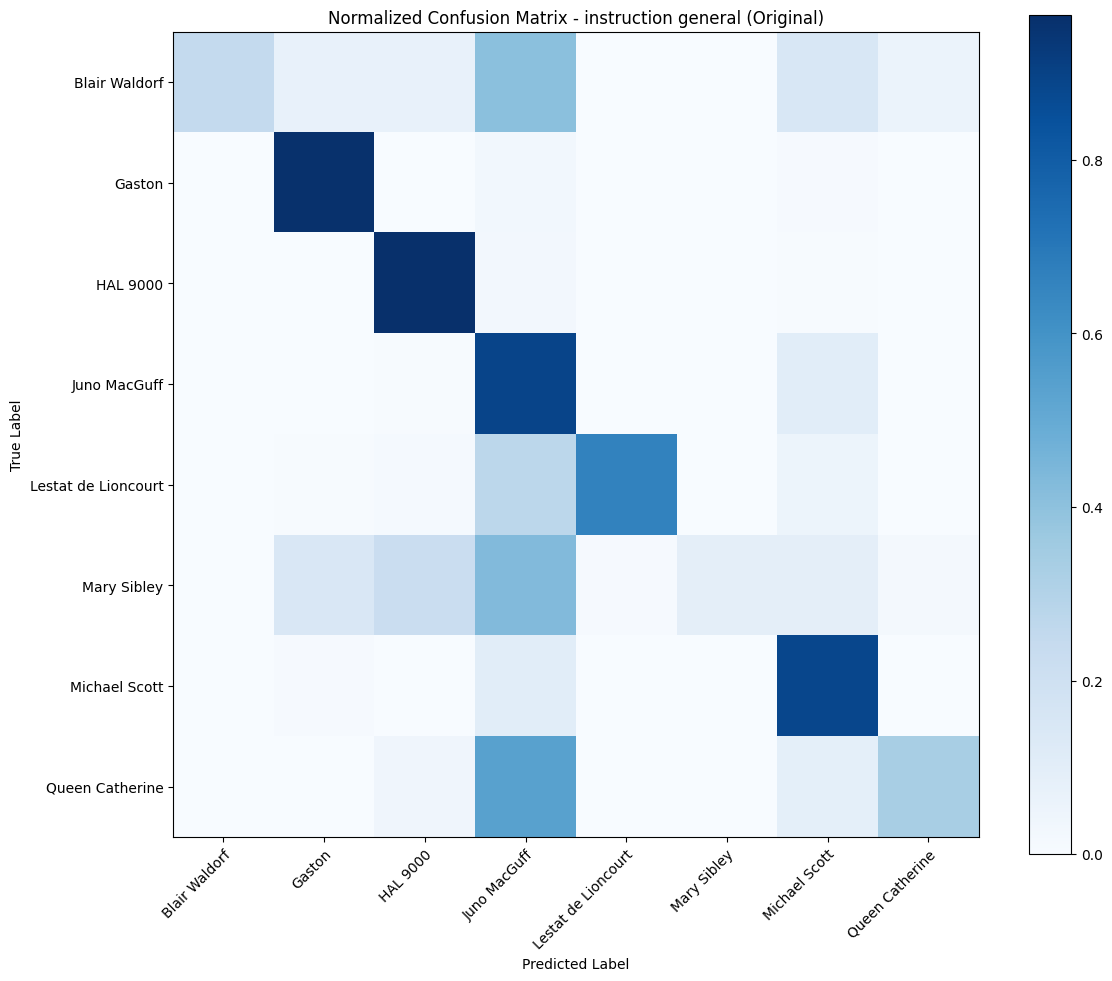

(                      role                                               text  \
 0      Lestat de Lioncourt  this is a classic ! the line " i am your fathe...   
 1      Lestat de Lioncourt  that paragraph contains a * * hyperbole * * . ...   
 2      Lestat de Lioncourt  never walk away angry . ( the sentence was alr...   
 3      Lestat de Lioncourt  this is a delightful challenge ! considering t...   
 4      Lestat de Lioncourt  * * relationship type :* * * * agent - object ...   
 ...                    ...                                                ...   
 26825      Queen Catherine  false . while prolonged rain can * damage * pl...   
 26826      Queen Catherine  here are the answers to your prompts , generat...   
 26827      Queen Catherine  ( she regards the data with a focused intensit...   
 26828      Queen Catherine  ( she considers the passage with a critical ey...   
 26829      Queen Catherine  this question – " should i start my own busine...   
 
              

In [5]:
name = "instruction general (Original)"
path = "/kaggle/input/new-roles-datasets/Cleaned/instruction_general.csv"

process_dataset(name, path)


Processing: instruction general (0)


Inferencing instruction general (0):   0%|          | 0/2373 [00:00<?, ?it/s]


Overall Accuracy: 28.07%

Top 8 Roles by Recall:


,label,support,tp,fp,fn,precision,recall,f1
0,Gaston,297,281,16,16,0.946128,0.946128,0.946128
1,Michael Scott,300,133,5,167,0.963768,0.443333,0.607306
2,HAL 9000,298,123,0,175,1.000000,0.412752,0.584323
3,Juno MacGuff,295,68,2,227,0.971429,0.230508,0.372603
4,Lestat de Lioncourt,293,32,1,261,0.969697,0.109215,0.196319
5,Queen Catherine,294,14,1,280,0.933333,0.047619,0.090615
6,Mary Sibley,298,9,0,289,1.000000,0.030201,0.058632
7,Blair Waldorf,298,6,0,292,1.000000,0.020134,0.039474



Generating Confusion Matrix for instruction general (0)...


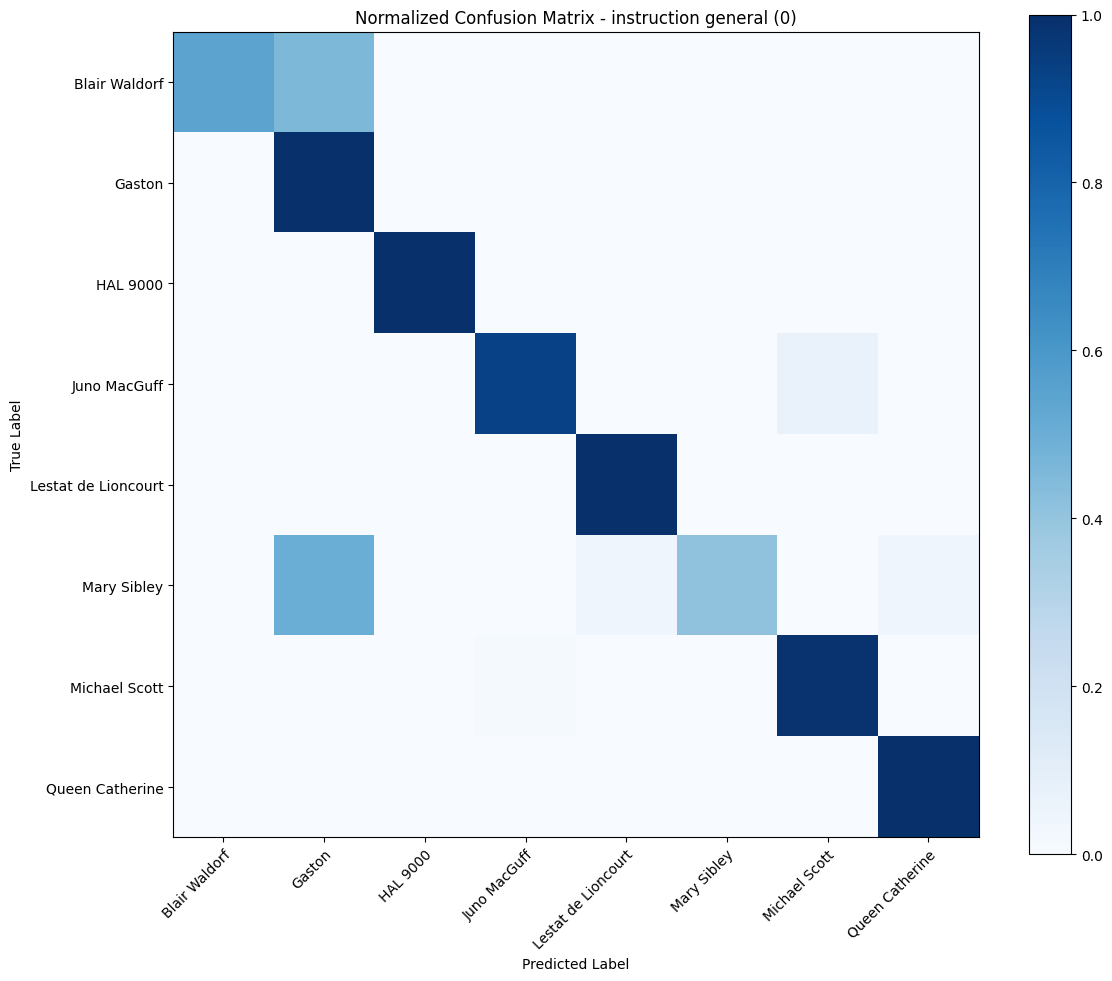

(               role                                               text  \
 0     Michael Scott  okay , okay , this is a * good * one . a * rea...   
 1     Michael Scott  okay , okay , hold the phone ! a question abou...   
 2     Michael Scott  okay , okay , hold the phone ! this is ... thi...   
 3     Michael Scott  okay , okay , hold the phone ! a math problem ...   
 4     Michael Scott  okay , okay , hold the phone ! this is ... thi...   
 ...             ...                                                ...   
 2678         Gaston  hmph . plants dying from a little rain ? prepo...   
 2679         Gaston  honestly , asking * me * about some commoner a...   
 2680         Gaston  hmph . linear functions , you say ? honestly ,...   
 2681         Gaston  hmph . a rather … * simple * observation , wou...   
 2682         Gaston  hmph . a friend asking * me * about starting a...   
 
                  pred      role_norm        pred_norm  correct  
 0       Michael Scott  michael 

In [6]:
name = "instruction general (0)"
path = "/kaggle/input/new-roles-datasets/Cleaned/instruction_general_0.csv"

process_dataset(name, path)


Processing: instruction general (102)


Inferencing instruction general (102):   0%|          | 0/2373 [00:00<?, ?it/s]


Overall Accuracy: 8.64%

Top 8 Roles by Recall:


,label,support,tp,fp,fn,precision,recall,f1
0,HAL 9000,298,96,14,202,0.872727,0.322148,0.470588
1,Gaston,297,63,2,234,0.969231,0.212121,0.348066
2,Juno MacGuff,295,26,77,269,0.252427,0.088136,0.130653
3,Michael Scott,300,17,17,283,0.500000,0.056667,0.101796
4,Lestat de Lioncourt,293,1,0,292,1.000000,0.003413,0.006803
5,Queen Catherine,294,1,1,293,0.500000,0.003401,0.006757
6,Blair Waldorf,298,1,0,297,1.000000,0.003356,0.006689
7,Mary Sibley,298,0,0,298,0.000000,0.000000,0.000000



Generating Confusion Matrix for instruction general (102)...


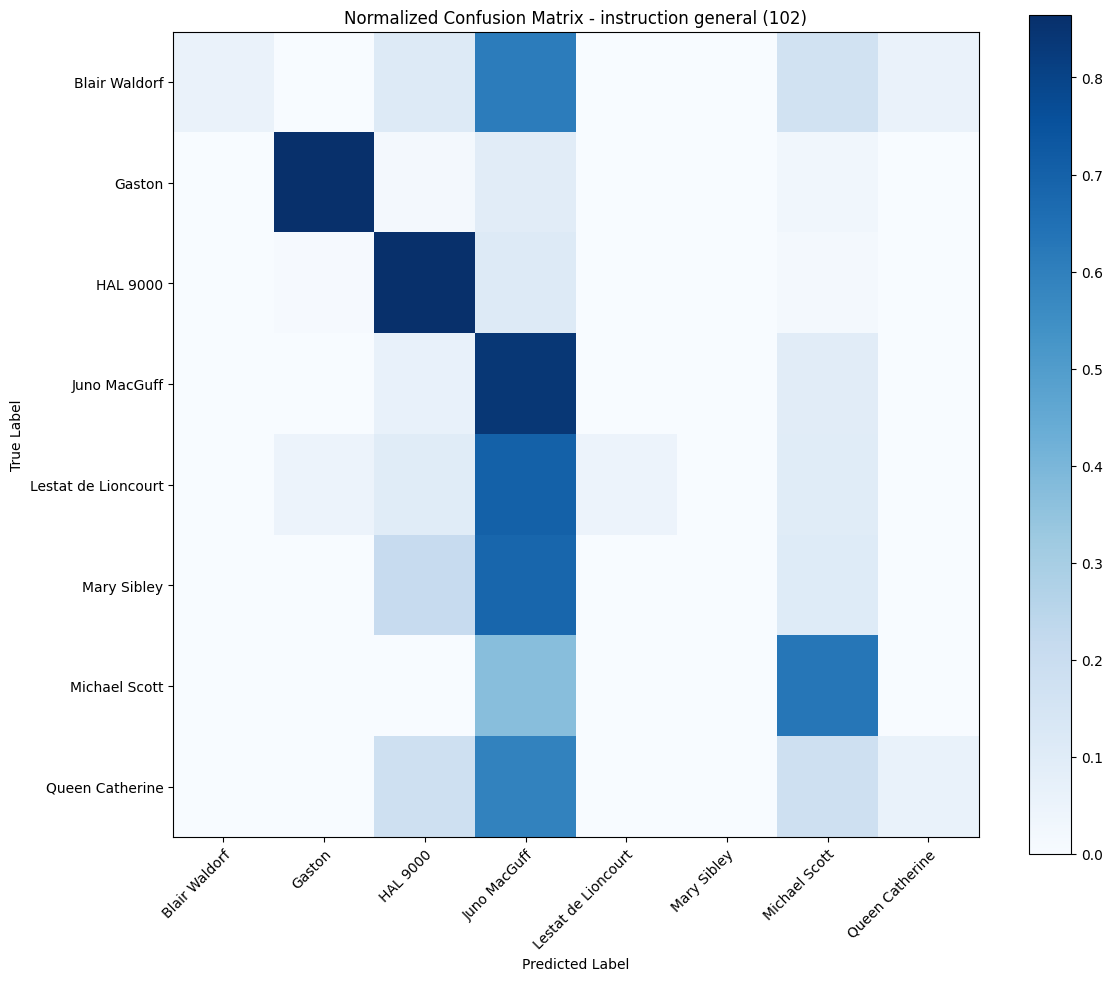

(                     role                                               text  \
 0     Lestat de Lioncourt  this is a classic ! the line " i am your fathe...   
 1     Lestat de Lioncourt  that paragraph contains a * * hyperbole * * . ...   
 2     Lestat de Lioncourt  never walk away angry . ( the sentence was alr...   
 3     Lestat de Lioncourt  this is a delightful challenge ! considering t...   
 4     Lestat de Lioncourt  * * relationship type :* * * * agent - object ...   
 ...                   ...                                                ...   
 2678        Michael Scott  false . while prolonged rain * can * contribut...   
 2679        Michael Scott  here are the answers to your prompts , generat...   
 2680        Michael Scott  ( adjusts tie , looks intensely at an imaginar...   
 2681        Michael Scott  ( adjusts tie , leans forward with a thoughtfu...   
 2682        Michael Scott  okay , let 's analyze this . * * * complexity ...   
 
                   pred   

In [7]:
name = "instruction general (102)"
path = "/kaggle/input/new-roles-datasets/Cleaned/instruction_general_102.csv"

process_dataset(name, path)

Final Results Summary: {'instruction general (Original)': 0.17008006742520018, 'instruction general (0)': 0.2806573957016435, 'instruction general (102)': 0.08638853771597134}


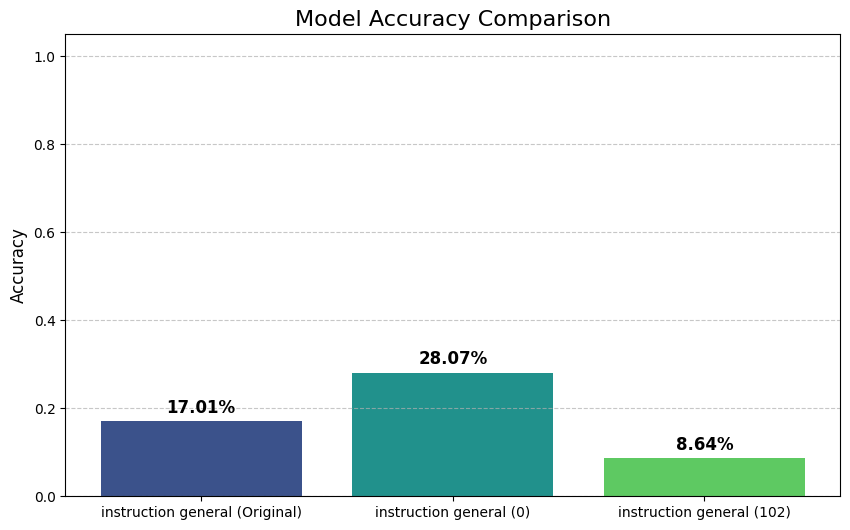

In [8]:
print("Final Results Summary:", GLOBAL_RESULTS)

if GLOBAL_RESULTS:
    plt.figure(figsize=(10, 6))
    
    names = list(GLOBAL_RESULTS.keys())
    values = list(GLOBAL_RESULTS.values())
    colors = sns.color_palette("viridis", len(names))
    
    bars = plt.bar(names, values, color=colors)
    
    plt.title("Model Accuracy Comparison", fontsize=16)
    plt.ylabel("Accuracy", fontsize=12)
    plt.ylim(0, 1.05)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    
    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                 f'{height:.2%}',
                 ha='center', va='bottom', fontsize=12, fontweight='bold')
    
    plt.show()
else:
    print("No results found.")